# Лабораторная работа № 2. Задание 3

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, cauchy
from scipy.optimize import brentq, minimize_scalar
from scipy.integrate import quad
from numpy.polynomial.legendre import leggauss

mu_true = 2.0
sigma_true = 1.0
target_efficiency = 0.95
seed = 42
q_normal = norm.ppf(0.75)

## 3.1. Нормальная модель с подстановкой MAD


Рассматриваем $X_i=\mu+\sigma U_i$, $U_i\sim N(0,1)$.
В численном примере $\mu=2$, $\sigma=1$; в оценивании оба параметра неизвестны.
Сначала вычисляем
$$\tilde x=\operatorname{Med}(x),\qquad
\operatorname{MAD}=\operatorname{Med}_i|x_i-\tilde x|,\qquad
\boxed{\hat\sigma=\frac{\operatorname{MAD}}{\Phi^{-1}(0.75)}}.$$
В нормальной модели необработанная MAD сходится к $\sigma\Phi^{-1}(0.75)$,
поэтому для оценки масштаба нужна нормировка, обычно называемая MADN.
Если требуется дисперсия, используем $\hat\sigma^2$; в стандартизованных
остатках делим на $\hat\sigma$.

При фиксированной найденной $\hat\sigma$ решаем
$$\sum_i\psi_c\!\left(\frac{x_i-\hat\mu}{\hat\sigma}\right)=0.$$
Используем
$$\psi_{H,c}(u)=\operatorname{clip}(u,-c,c),\qquad
\psi_{B,c}(u)=u(1-u^2/c^2)^2\mathbf1_{|u|<c}.$$
Масштаб вычисляется относительно медианы и при поиске положения уже не меняется.
Для bisquare выбираем устойчивую центральную ветвь: итерации начинаются в медиане.

In [2]:
def psi(u, c, kind):
    u = np.asarray(u, dtype=float)
    if kind == 'Huber':
        return np.clip(u, -c, c)
    ratio = np.minimum(np.abs(u) / c, 1.0)
    return u * (1 - ratio**2)**2

def psi_prime(u, c, kind):
    u = np.asarray(u, dtype=float)
    if kind == 'Huber':
        return (np.abs(u) < c).astype(float)
    ratio = np.minimum(np.abs(u) / c, 1.0)
    return (1 - ratio**2) * (1 - 5 * ratio**2)

def mad_scale(samples, q):
    samples = np.asarray(samples, dtype=float)
    medians = np.median(samples, axis=-1)
    return np.median(np.abs(samples - np.expand_dims(medians, -1)), axis=-1) / q

def batch_location(samples, scales, c, kind, tol=1e-10, max_iter=500):
    # Одна строка — одна выборка; для каждой используется своя оценка масштаба.
    samples = np.asarray(samples, dtype=float)
    scales = np.asarray(scales, dtype=float)
    locations = np.median(samples, axis=1)
    valid = np.isfinite(scales) & (scales > 0) & np.isfinite(samples).all(axis=1)
    safe_scales = np.where(valid, scales, 1.0)
    converged = np.zeros(len(samples), dtype=bool)

    for iteration in range(max_iter):
        active = valid & ~converged
        if not active.any():
            break
        residuals = (samples[active] - locations[active, None]) / safe_scales[active, None]
        if kind == 'Huber':
            weights = np.minimum(1.0, c / np.maximum(np.abs(residuals), 1e-300))
        else:
            ratio = np.minimum(np.abs(residuals) / c, 1.0)
            weights = (1 - ratio**2)**2
        denominators = weights.sum(axis=1)
        indices = np.flatnonzero(active)
        good = denominators > 0
        valid[indices[~good]] = False
        indices = indices[good]
        if not len(indices):
            continue
        new_locations = (weights[good] * samples[indices]).sum(axis=1) / denominators[good]
        converged[indices] = np.abs(new_locations - locations[indices]) <= tol * safe_scales[indices]
        locations[indices] = new_locations

    residuals = (samples - locations[:, None]) / safe_scales[:, None]
    score_error = np.abs(psi(residuals, c, kind).mean(axis=1))
    derivative = psi_prime(residuals, c, kind).mean(axis=1)
    success = valid & converged & (score_error < 1e-7) & (derivative > 0)
    locations[~success] = np.nan
    return locations

## 3.2. Выбор параметров для эффективности $\Delta=0.95$

Положим $A_F(c)=E_F\psi'_c(U)$, $B_F(c)=E_F\psi_c(U)^2$.
Тогда для центрального состоятельного решения
$$\sqrt n(\hat\mu-\mu)\Rightarrow
N\!\left(0,\sigma^2 V_F(c)\right),\qquad
\boxed{V_F(c)=\frac{B_F(c)}{A_F(c)^2}}.$$
Подстановка состоятельной MADN не меняет этот коэффициент первого порядка:
производная уравнения положения по масштабу пропорциональна
$E_F[U\psi'_c(U)]=0$ вследствие симметрии $F$ и чётности $\psi'_c$.
Это обоснование относится к симметричной незагрязнённой модели.

У среднего в нормальной модели коэффициент дисперсии равен 1, поэтому
$$\operatorname{Eff}_N(c)=\frac{1}{V_N(c)},\qquad
\operatorname{Eff}_N(c)=0.95.$$
Для Губера интегралы учитывают постоянное значение $\psi$ в хвостах;
у bisquare интегрирование достаточно проводить по $[-c,c]$.

In [3]:
def score_moments(kind, c, model='normal'):
    law = norm if model == 'normal' else cauchy
    if kind == 'Huber':
        a = 1 - 2 * law.sf(c)
        b = 2 * quad(lambda u: u**2 * law.pdf(u), 0, c,
                     epsabs=1e-10, epsrel=1e-10)[0] + 2 * c**2 * law.sf(c)
    else:
        a = 2 * quad(lambda u: psi_prime(u, c, kind) * law.pdf(u), 0, c,
                     epsabs=1e-10, epsrel=1e-10)[0]
        b = 2 * quad(lambda u: psi(u, c, kind)**2 * law.pdf(u), 0, c,
                     epsabs=1e-10, epsrel=1e-10)[0]
    return a, b, b / a**2

c_huber = brentq(lambda c: 1 / score_moments('Huber', c)[2] - target_efficiency,
                 0.05, 5, xtol=1e-12)
c_bisquare = brentq(lambda c: 1 / score_moments('Bisquare', c)[2] - target_efficiency,
                    0.5, 12, xtol=1e-12)
settings = {'Huber': c_huber, 'Bisquare': c_bisquare}
normal_moments = {kind: score_moments(kind, c) for kind, c in settings.items()}

calibration = pd.DataFrame([
    [kind, c, *normal_moments[kind], 1 / normal_moments[kind][2]]
    for kind, c in settings.items()
], columns=['Метод', 'c', 'A_N', 'B_N', 'V_N', 'Эффективность'])
display(calibration.round(8))
assert np.allclose(calibration['Эффективность'], target_efficiency, atol=1e-10)

rng = np.random.default_rng(seed)
x = rng.normal(mu_true, sigma_true, size=100)
sigma_hat = mad_scale(x, q_normal)
example_rows = [['Медиана', np.median(x)]]
for kind, c in settings.items():
    value = batch_location(x[None, :], np.array([sigma_hat]), c, kind)[0]
    example_rows.append([kind, value])
print(f'MADN на выборке n=100: {sigma_hat:.6f}; оценка дисперсии: {sigma_hat**2:.6f}')
display(pd.DataFrame(example_rows, columns=['Метод', 'Оценка mu']).round(6))

,Метод,c,A_N,B_N,V_N,Эффективность
0,Huber,1.344998,0.821374,0.710163,1.052632,0.95
1,Bisquare,4.685065,0.757782,0.604456,1.052632,0.95


MADN на выборке n=100: 0.800435; оценка дисперсии: 0.640696


,Метод,Оценка mu
0,Медиана,1.997846
1,Huber,1.963882
2,Bisquare,1.961295


Получены $c_H\approx1.34500$ и $c_B\approx4.68506$.
У обеих настроек $V_N=1/0.95\approx1.05263$.
Следовательно, асимптотическая дисперсия каждой оценки положения равна
$\sigma^2/(0.95n)$.

Проверим также эффект подстановки масштаба моделированием.
Для MADN коэффициент дисперсии получается из квантильного представления:
$$V_{s,N}=\frac{1}{16q_N^2\varphi(q_N)^2},\qquad q_N=\Phi^{-1}(0.75).$$
В каждом повторении масштаб оценивается заново по той же выборке.

In [4]:
def variance_experiment(model, repeats, sample_sizes, rng_seed, q_scale, theory):
    rng = np.random.default_rng(rng_seed)
    rows = []
    for n in sample_sizes:
        if model == 'normal':
            samples = rng.normal(mu_true, sigma_true, size=(repeats, n))
        else:
            samples = mu_true + sigma_true * rng.standard_cauchy(size=(repeats, n))
        scales = mad_scale(samples, q_scale)
        values = {'Медиана': np.median(samples, axis=1), 'MAD (масштаб)': scales}
        for kind, c in settings.items():
            values[kind] = batch_location(samples, scales, c, kind)
        for name in ['Медиана', 'Huber', 'Bisquare', 'MAD (масштаб)']:
            estimates = values[name]
            good = estimates[np.isfinite(estimates)]
            target = sigma_true if name == 'MAD (масштаб)' else mu_true
            empirical = n * np.var(good, ddof=1) / sigma_true**2
            bias = good.mean() - target
            mcse = np.std(good, ddof=1) / np.sqrt(len(good))
            rows.append([n, name, theory[name], empirical, empirical / theory[name],
                         bias, mcse, repeats - len(good)])
        print(f'{model}: n={n}, повторений={repeats}')
    return pd.DataFrame(rows, columns=['n', 'Метод', 'V теория', 'n Var / sigma²',
                                      'Отношение', 'Смещение', 'MCSE смещения', 'Сбоев'])

v_mad_normal = 1 / (16 * q_normal**2 * norm.pdf(q_normal)**2)
normal_theory = {'Медиана': np.pi / 2,
                 'Huber': normal_moments['Huber'][2],
                 'Bisquare': normal_moments['Bisquare'][2],
                 'MAD (масштаб)': v_mad_normal}
normal_check = variance_experiment('normal', repeats=1000, sample_sizes=[100, 500, 1000],
                                   rng_seed=43, q_scale=q_normal, theory=normal_theory)
display(normal_check.round(5))

normal: n=100, повторений=1000
normal: n=500, повторений=1000
normal: n=1000, повторений=1000


,n,Метод,V теория,n Var / sigma²,Отношение,Смещение,MCSE смещения,Сбоев
0,100,Медиана,1.57080,1.52237,0.96917,-0.00299,0.00390,0
1,100,Huber,1.05263,0.98572,0.93643,-0.00267,0.00314,0
2,100,Bisquare,1.05263,0.98720,0.93784,-0.00306,0.00314,0
3,100,MAD (масштаб),1.36046,1.25353,0.92141,-0.00743,0.00354,0
4,500,Медиана,1.57080,1.42036,0.90423,-0.00156,0.00169,0
5,500,Huber,1.05263,0.98568,0.93640,-0.00098,0.00140,0
6,500,Bisquare,1.05263,0.98561,0.93633,-0.00110,0.00140,0
7,500,MAD (масштаб),1.36046,1.34701,0.99011,0.00079,0.00164,0
8,1000,Медиана,1.57080,1.49380,0.95098,-0.00006,0.00122,0
9,1000,Huber,1.05263,1.05764,1.00475,0.00049,0.00103,0


## 3.3. Gross-error sensitivity и maximum bias

В нормальной модели функция влияния положения равна
$$\operatorname{IF}(z;T,F)=\sigma\frac{\psi_c(u)}{A_N(c)},\qquad
u=\frac{z-\mu}{\sigma}.$$
Следовательно,
$$\gamma_H^*=\sigma\frac{c_H}{A_N(c_H)},\qquad
\gamma_B^*=\sigma\frac{16c_B}{25\sqrt5\,|A_N(c_B)|}.$$
У bisquare максимум достигается при $|u|=c_B/\sqrt5$.

Для загрязнения $F_{\varepsilon,z}=(1-\varepsilon)F+\varepsilon\delta_z$
по определению функции влияния
$$b(\varepsilon,z)=T(F_{\varepsilon,z})-T(F)
=\varepsilon\operatorname{IF}(z;T,F)+o(\varepsilon).$$
Поэтому локальная оценка максимального по точке загрязнения смещения:
$$\boxed{B_{\mathrm{local}}(\varepsilon)\approx\varepsilon\gamma^*}.$$
В скобках подпункта 3 условия предлагается делить GES на долю выбросов.
По приведённому разложению здесь нужно **умножение**; деление смещения на
$\varepsilon$ приближает функцию влияния, а не наоборот.

При фиксированном немалом $\varepsilon$ это лишь линейное приближение.
Далее вычисляем нелинейное асимптотическое смещение по точечным загрязнениям.
Максимум по всем возможным распределениям загрязнения и максимум только
по $\delta_z$ — разные задачи; численный эксперимент ниже относится ко второй.

,Метод,GES
0,Huber,1.637497
1,Bisquare,1.769565


,epsilon,Метод,epsilon × GES
0,0.01,Huber,0.016375
1,0.01,Bisquare,0.017696
2,0.05,Huber,0.081875
3,0.05,Bisquare,0.088478
4,0.10,Huber,0.163750
5,0.10,Bisquare,0.176956
6,0.20,Huber,0.327499
7,0.20,Bisquare,0.353913


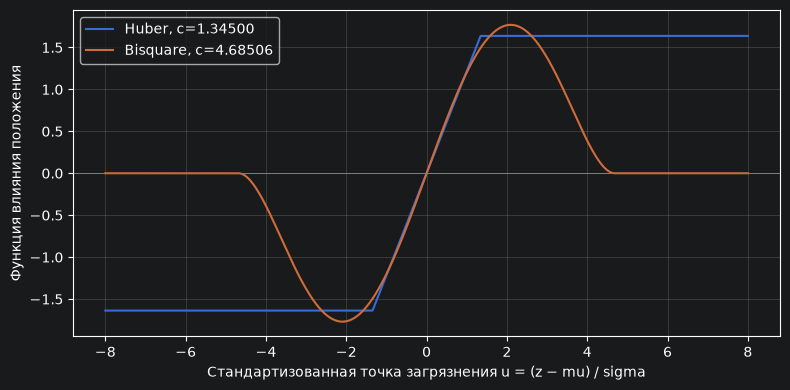

In [5]:
ges = {'Huber': sigma_true * c_huber / normal_moments['Huber'][0],
       'Bisquare': sigma_true * 16 * c_bisquare /
                   (25 * np.sqrt(5) * abs(normal_moments['Bisquare'][0]))}
display(pd.DataFrame({'Метод': list(ges), 'GES': list(ges.values())}).round(6))

contamination_levels = [0.01, 0.05, 0.10, 0.20]
local_bias_table = pd.DataFrame([
    [epsilon, kind, epsilon * ges[kind]]
    for epsilon in contamination_levels for kind in settings
], columns=['epsilon', 'Метод', 'epsilon × GES'])
display(local_bias_table.round(6))

u_grid = np.linspace(-8, 8, 1601)
plt.figure(figsize=(8, 4))
for kind, c in settings.items():
    influence = sigma_true * psi(u_grid, c, kind) / normal_moments[kind][0]
    plt.plot(u_grid, influence, label=f'{kind}, c={c:.5f}')
plt.axhline(0, color='gray', linewidth=0.7)
plt.xlabel('Стандартизованная точка загрязнения u = (z − mu) / sigma')
plt.ylabel('Функция влияния положения')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 3.4. Asymptotic bias при точечном загрязнении

Работаем в стандартизованных координатах:
$$G_{\varepsilon,u}=(1-\varepsilon)N(0,1)+\varepsilon\delta_u.$$
При каждом $u$ оцениваем масштаб заново: используем популяционный аналог
той же MADN, а не истинное значение 1.
Пусть $m=\operatorname{Med}(G_{\varepsilon,u})$,
$r=\operatorname{Med}_{G_{\varepsilon,u}}|U-m|$ и $s=r/q_N$.
Для $\varepsilon<1/2$ медиану удобно записать как
$$m=\operatorname{clip}\!\left(u,
\Phi^{-1}\!\left(\frac{1/2-\varepsilon}{1-\varepsilon}\right),
\Phi^{-1}\!\left(\frac{1/2}{1-\varepsilon}\right)\right).$$
Распределение $|U-m|$ состоит из непрерывной части
$(1-\varepsilon)[\Phi(m+r)-\Phi(m-r)]$ и атома массы $\varepsilon$ при $r=|u-m|$.
Это позволяет найти его медиану с точным учётом скачка.

Далее ищем центральное решение $t$ уравнения
$$ (1-\varepsilon)\int\psi_c\!\left(\frac{v-t}{s}\right)\varphi(v)\,dv
+\varepsilon\psi_c\!\left(\frac{u-t}{s}\right)=0.$$
Смещение в исходных единицах равно $\sigma t$.
У Губера корень единственен; у bisquare используем итерации с началом в $m$
и проверяем положительность средней производной и невязку уравнения.

In [6]:
nodes, node_weights = leggauss(96)

def contaminated_mad(u, epsilon):
    if not 0 <= epsilon < 0.5:
        raise ValueError('Для этого расчёта требуется 0 <= epsilon < 0.5')
    p_low = (0.5 - epsilon) / (1 - epsilon)
    p_high = 0.5 / (1 - epsilon)
    median = np.clip(u, norm.ppf(p_low), norm.ppf(p_high))
    def clean_abs_cdf(r):
        return norm.cdf(median + r) - norm.cdf(median - r)
    r_low = brentq(lambda r: clean_abs_cdf(r) - p_low, 0, 10, xtol=1e-12)
    r_high = brentq(lambda r: clean_abs_cdf(r) - p_high, 0, 10, xtol=1e-12)
    mad = np.clip(abs(u - median), r_low, r_high)
    return float(median), float(mad / q_normal)

def normal_huber_score(t, scale, c):
    a, b = t - scale * c, t + scale * c
    inside = (norm.pdf(a) - norm.pdf(b) - t * (norm.cdf(b) - norm.cdf(a))) / scale
    return inside + c * (norm.sf(b) - norm.cdf(a))

def normal_bisquare_weights(t, scale, c):
    # Интегрируем по конечному носителю весов, не обрезая нормальное распределение.
    v = t + scale * c * nodes
    integration_weights = scale * c * node_weights * norm.pdf(v)
    weights = (1 - nodes**2)**2
    denominator = np.sum(integration_weights * weights)
    numerator = np.sum(integration_weights * weights * v)
    derivative = np.sum(integration_weights * (1 - nodes**2) * (1 - 5 * nodes**2))
    return denominator, numerator, derivative

def population_location(u, epsilon, kind, c):
    median, scale = contaminated_mad(u, epsilon)
    if kind == 'Huber':
        def equation(t):
            return ((1 - epsilon) * normal_huber_score(t, scale, c)
                    + epsilon * psi((u - t) / scale, c, kind))
        bound = max(10.0, abs(u) + 1)
        return brentq(equation, -bound, bound, xtol=1e-12)

    t = median
    for iteration in range(1000):
        den, num, derivative = normal_bisquare_weights(t, scale, c)
        ratio = min(abs((u - t) / (scale * c)), 1.0)
        atom_weight = (1 - ratio**2)**2
        total_den = (1 - epsilon) * den + epsilon * atom_weight
        t_new = ((1 - epsilon) * num + epsilon * atom_weight * u) / total_den
        if abs(t_new - t) < 1e-11 * scale:
            den, num, derivative = normal_bisquare_weights(t_new, scale, c)
            residual = (u - t_new) / scale
            score = (1 - epsilon) * (num - t_new * den) / scale + epsilon * psi(residual, c, kind)
            slope = (1 - epsilon) * derivative + epsilon * psi_prime(residual, c, kind)
            if abs(score) > 1e-8 or slope <= 0:
                raise RuntimeError('Неподходящий корень популяционного уравнения bisquare')
            return float(t_new)
        t = t_new
    raise RuntimeError('Популяционная итерация bisquare не сошлась')

Кривые смещения рассчитаны: epsilon=0.01
Кривые смещения рассчитаны: epsilon=0.05
Кривые смещения рассчитаны: epsilon=0.10
Кривые смещения рассчитаны: epsilon=0.20


,epsilon,Метод,Локально: epsilon × GES,Численный max по delta_z,Точка u*
0,0.01,Huber,0.016375,0.016634,дальние выбросы
1,0.01,Bisquare,0.017696,0.017970,2.1381
2,0.05,Huber,0.081875,0.088946,дальние выбросы
3,0.05,Bisquare,0.088478,0.096024,2.3266
4,0.10,Huber,0.163750,0.195757,дальние выбросы
5,0.10,Bisquare,0.176956,0.211370,2.6101
6,0.20,Huber,0.327499,0.502136,дальние выбросы
7,0.20,Bisquare,0.353913,0.543313,3.4406


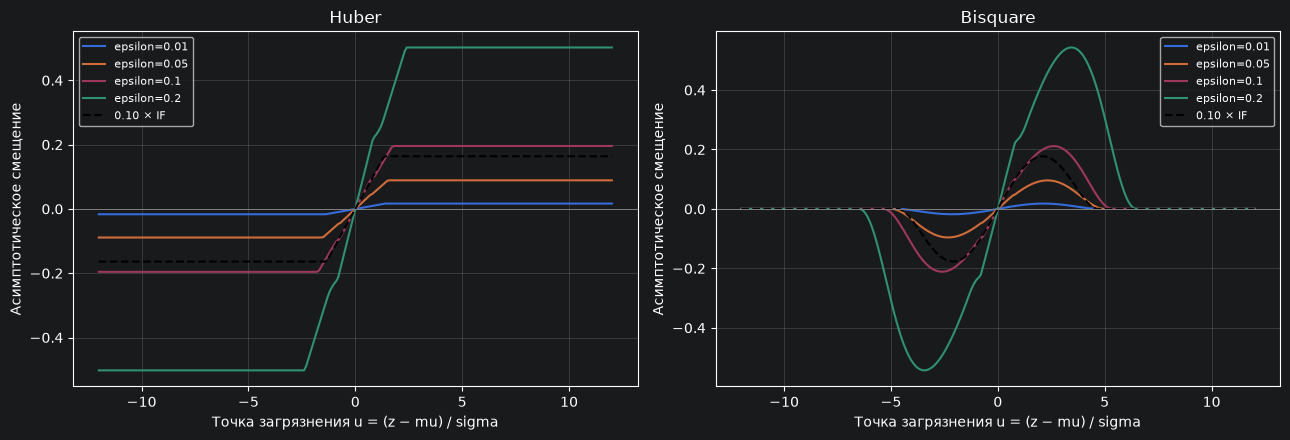

In [7]:
z_grid = np.linspace(-12, 12, 241)  # Значения u; физическая точка равна mu + sigma*u.
bias_curves = {}
max_bias_rows = []

for epsilon in contamination_levels:
    for kind, c in settings.items():
        curve = sigma_true * np.array([population_location(u, epsilon, kind, c) for u in z_grid])
        bias_curves[(kind, epsilon)] = curve
        assert np.max(np.abs(curve + curve[::-1])) < 1e-7
        positive = np.flatnonzero(z_grid >= 0)
        index = positive[np.argmax(np.abs(curve[positive]))]
        if kind == 'Huber':
            # Для u -> +infinity вклад атома равен c; MAD достигает предельного значения.
            scale_inf = contaminated_mad(1000, epsilon)[1]
            maximum = sigma_true * brentq(
                lambda t: (1 - epsilon) * normal_huber_score(t, scale_inf, c) + epsilon * c,
                0, 20)
            worst_point = 'дальние выбросы'
        else:
            lo, hi = z_grid[max(index - 1, 0)], z_grid[min(index + 1, len(z_grid) - 1)]
            optimum = minimize_scalar(
                lambda u: -abs(population_location(u, epsilon, kind, c)),
                bounds=(lo, hi), method='bounded', options={'xatol': 1e-8})
            maximum = sigma_true * abs(population_location(optimum.x, epsilon, kind, c))
            worst_point = f'{optimum.x:.4f}'
        max_bias_rows.append([epsilon, kind, epsilon * ges[kind], maximum, worst_point])
    print(f'Кривые смещения рассчитаны: epsilon={epsilon:.2f}')

max_bias = pd.DataFrame(max_bias_rows,
    columns=['epsilon', 'Метод', 'Локально: epsilon × GES', 'Численный max по delta_z', 'Точка u*'])
display(max_bias.round(6))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (kind, c) in zip(axes, settings.items()):
    for epsilon in contamination_levels:
        ax.plot(z_grid, bias_curves[(kind, epsilon)], label=f'epsilon={epsilon:g}')
    local = 0.10 * sigma_true * psi(z_grid, c, kind) / normal_moments[kind][0]
    ax.plot(z_grid, local, '--', color='black', label='0.10 × IF')
    ax.axhline(0, color='gray', linewidth=0.7)
    ax.set(xlabel='Точка загрязнения u = (z − mu) / sigma',
           ylabel='Асимптотическое смещение', title=kind)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Для Губера смещение выходит на ненулевое плато: очень далёкие выбросы
продолжают давать вклад $\pm c_H$ в уравнение.
У центральной bisquare-оценки смещение возвращается к нулю,
когда точка загрязнения оказывается вне области ненулевых весов.
Наиболее неблагоприятны для неё выбросы промежуточной величины.
Сама MADN при загрязнении также меняется, поэтому нелинейные кривые
при заметных $\varepsilon$ могут существенно отличаться от $\varepsilon\operatorname{IF}$.

Дополнительно проверим, что при очень малом загрязнении
$b(\varepsilon,z)/\varepsilon$ действительно приближает функцию влияния.

In [8]:
epsilon_small = 1e-5
check_points = np.linspace(-8, 8, 65)
for kind, c in settings.items():
    numerical_if = sigma_true * np.array([
        population_location(u, epsilon_small, kind, c) for u in check_points
    ]) / epsilon_small
    theoretical_if = sigma_true * psi(check_points, c, kind) / normal_moments[kind][0]
    error = np.max(np.abs(numerical_if - theoretical_if))
    print(f'{kind}: max |bias/epsilon - IF| = {error:.8f}')
    assert error < 0.002

Huber: max |bias/epsilon - IF| = 0.00002538
Bisquare: max |bias/epsilon - IF| = 0.00006577


### Проверка популяционного смещения моделированием

Фиксируем $\varepsilon=0.10$, $n=500$ и $R=400$ повторений.
В каждой нормальной выборке заменяем первые $m=\varepsilon n=50$ наблюдений
одним значением $z=\mu+\sigma u$. Доля замен фиксирована;
при росте $n$ эмпирическое распределение сходится к выбранной смеси.
Для разных точек $u$ и обоих методов используем одни и те же исходные выборки.

Для каждой загрязнённой выборки заново вычисляем MADN и M-оценки положения.
Среднее $\hat\mu-\mu$ сравниваем с популяционным смещением;
полосы $\pm2\operatorname{MCSE}$ характеризуют точность среднего по повторениям.
Это конечная выборочная проверка, поэтому точного совпадения кривых не требуется.

,u,Метод,Популяционное смещение,Среднее смещение,MCSE,Сбоев
0,-8.0,Huber,-0.195757,-0.195519,0.002401,0
1,-8.0,Bisquare,-0.000000,-0.000190,0.002380,0
20,-4.0,Huber,-0.195757,-0.195519,0.002401,0
21,-4.0,Bisquare,-0.121287,-0.119955,0.002988,0
30,-2.0,Huber,-0.195757,-0.195519,0.002401,0
31,-2.0,Bisquare,-0.195311,-0.195032,0.002259,0
40,0.0,Huber,0.000000,-0.000400,0.002126,0
41,0.0,Bisquare,0.000000,-0.000598,0.002126,0
50,2.0,Huber,0.195757,0.195725,0.002431,0
51,2.0,Bisquare,0.195311,0.194809,0.002281,0


Всего неудачных решений: 0


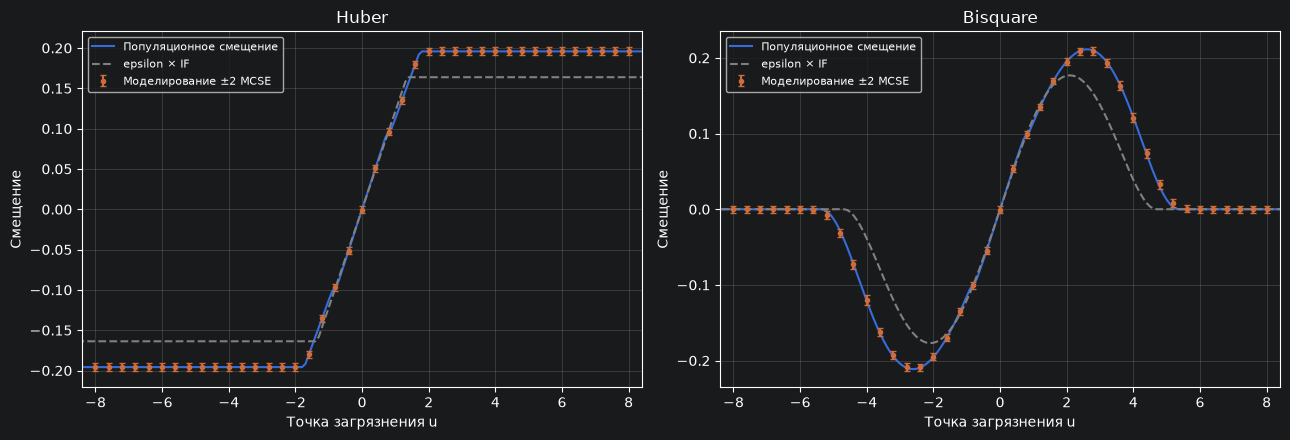

In [9]:
epsilon_mc = 0.10
n_mc = 500
repeats_mc = 400
z_mc = np.linspace(-8, 8, 41)
m_mc = round(epsilon_mc * n_mc)
rng_mc = np.random.default_rng(44)
clean_samples = rng_mc.normal(mu_true, sigma_true, size=(repeats_mc, n_mc))
mc_rows = []

for u in z_mc:
    samples = clean_samples.copy()
    samples[:, :m_mc] = mu_true + sigma_true * u
    scales = mad_scale(samples, q_normal)
    for kind, c in settings.items():
        estimates = batch_location(samples, scales, c, kind)
        good = estimates[np.isfinite(estimates)]
        empirical_bias = np.mean(good - mu_true)
        mcse = np.std(good, ddof=1) / np.sqrt(len(good))
        population_bias = sigma_true * population_location(u, epsilon_mc, kind, c)
        mc_rows.append([u, kind, population_bias, empirical_bias, mcse, repeats_mc - len(good)])

bias_check = pd.DataFrame(mc_rows,
    columns=['u', 'Метод', 'Популяционное смещение', 'Среднее смещение', 'MCSE', 'Сбоев'])
selected_points = [-8, -4, -2, 0, 2, 4, 8]
selected_rows = np.isclose(bias_check['u'].to_numpy()[:, None], selected_points).any(axis=1)
display(bias_check[selected_rows].round(6))
print('Всего неудачных решений:', int(bias_check['Сбоев'].sum()))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (kind, c) in zip(axes, settings.items()):
    rows = bias_check[bias_check['Метод'] == kind]
    ax.plot(z_grid, bias_curves[(kind, epsilon_mc)], label='Популяционное смещение')
    ax.errorbar(rows['u'], rows['Среднее смещение'], yerr=2 * rows['MCSE'],
                fmt='o', markersize=3, capsize=2, label='Моделирование ±2 MCSE')
    ax.plot(z_grid, epsilon_mc * sigma_true * psi(z_grid, c, kind) / normal_moments[kind][0],
            '--', color='gray', label='epsilon × IF')
    ax.set(xlim=(-8.4, 8.4), xlabel='Точка загрязнения u', ylabel='Смещение', title=kind)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

При $\varepsilon=0.1$ локальные оценки максимального смещения равны
0.16375 для Губера и 0.17696 для bisquare. Нелинейный расчёт даёт соответственно
0.19576 и 0.21137. Для bisquare максимум достигается около $u=2.6101$.
Значит, при 10% загрязнения линейная оценка уже заметно занижает максимум.
В моделировании при $u=8$ среднее смещение Губера равно примерно 0.19573,
а bisquare — около $-0.00007$; это согласуется с популяционными кривыми.

## 3.5. M-оценки для распределения Коши

Теперь $X_i=\mu+\gamma U_i$, $U_i\sim\operatorname{Cauchy}(0,1)$,
$$f_C(u)=\frac{1}{\pi(1+u^2)},\qquad
F_C(u)=\frac12+\frac{\arctan u}{\pi}.$$
Параметр $\gamma>0$ — масштаб распределения Коши; его дисперсия не существует.
В численном примере используем $\mu=2$, $\gamma=1$.
Переменная `sigma_true` в общем коде моделирования здесь обозначает $\gamma$.

Настройки **не подбираем заново**: используем найденные
$c_H\approx1.34500$, $c_B\approx4.68506$.
Поскольку $F_C^{-1}(0.75)=1$, состоятельная оценка масштаба здесь равна
$$\boxed{\hat\gamma=\operatorname{MAD}}.$$
Нормальную поправку $1/\Phi^{-1}(0.75)$ для этой модели применять не нужно.
После подстановки $\hat\gamma$ решаем те же уравнения положения.

Симметрия снова даёт $E_C[U\psi'_c(U)]=0$, поэтому
$$\sqrt n(\hat\mu-\mu)\Rightarrow N(0,\gamma^2V_C),\qquad
\boxed{V_C=\frac{E_C\psi_c(U)^2}{(E_C\psi'_c(U))^2}}.$$
Для Губера
$$A_{C,H}=\frac2\pi\arctan c,\qquad
B_{C,H}=\frac2\pi(c-\arctan c)
+c^2\left(1-\frac2\pi\arctan c\right).$$
Для bisquare считаем интегралы с плотностью $f_C$ по $[-c,c]$.
Ограниченность $\psi$ обеспечивает конечность числителя, несмотря на тяжёлые хвосты Коши.

In [10]:
cauchy_moments = {kind: score_moments(kind, c, 'cauchy') for kind, c in settings.items()}
cauchy_theory_table = pd.DataFrame([
    [kind, c, *cauchy_moments[kind], 2 / cauchy_moments[kind][2]]
    for kind, c in settings.items()
], columns=['Метод', 'c', 'A_C', 'B_C', 'V_C', 'Эффективность к границе 2'])
display(cauchy_theory_table.round(7))

# Независимая проверка интегрального выражения для Губера.
a_h_cauchy = 2 * np.arctan(c_huber) / np.pi
b_h_cauchy = 2 * (c_huber - np.arctan(c_huber)) / np.pi + c_huber**2 * (1 - a_h_cauchy)
assert np.allclose(cauchy_moments['Huber'][:2], [a_h_cauchy, b_h_cauchy], atol=1e-10)

,Метод,c,A_C,B_C,V_C,Эффективность к границе 2
0,Huber,1.344998,0.592993,0.999543,2.842513,0.703603
1,Bisquare,4.685065,0.492092,0.569133,2.350286,0.850960


Получено
$$V_{C,H}\approx2.84251,\qquad V_{C,B}\approx2.35029.$$
Соответствующие асимптотические дисперсии оценок положения:
$$\operatorname{Var}(\hat\mu_H)\approx\frac{2.84251\gamma^2}{n},\qquad
\operatorname{Var}(\hat\mu_B)\approx\frac{2.35029\gamma^2}{n}.$$
Для справки, информация Фишера о положении равна $1/(2\gamma^2)$,
поэтому эффективная граница коэффициента дисперсии равна 2.
Нормальная эффективность 95% не переносится на распределение Коши.

Проверим также масштаб. Для симметричной модели с $q=F^{-1}(0.75)$
функция влияния калиброванной MAD имеет вид
$$\operatorname{IF}_s(x)=\frac{\gamma}{4qf(q)}
\left(1-2\mathbf1_{|(x-\mu)/\gamma|\le q}\right).$$
При Коши $q=1$, $f_C(1)=1/(2\pi)$, поэтому
$$\sqrt n(\hat\gamma-\gamma)\Rightarrow
N\!\left(0,\gamma^2\frac{\pi^2}{4}\right).$$
У медианы положения также $V_{C,\mathrm{Med}}=\pi^2/4$.
Функция влияния положения нечётна, масштаба — чётна; их асимптотическая ковариация равна нулю.

cauchy: n=100, повторений=2000
cauchy: n=500, повторений=2000
cauchy: n=1000, повторений=2000


,n,Метод,V теория,n Var / sigma²,Отношение,Смещение,MCSE смещения,Сбоев
0,100,Медиана,2.46740,2.46576,0.99933,-0.00084,0.00351,0
1,100,Huber,2.84251,2.94427,1.03580,-0.00042,0.00384,0
2,100,Bisquare,2.35029,2.47114,1.05142,-0.00304,0.00352,0
3,100,MAD (масштаб),2.46740,2.61566,1.06009,0.00857,0.00362,0
4,500,Медиана,2.46740,2.53022,1.02546,-0.00166,0.00159,0
5,500,Huber,2.84251,2.90302,1.02129,-0.00140,0.00170,0
6,500,Bisquare,2.35029,2.40895,1.02496,-0.00093,0.00155,0
7,500,MAD (масштаб),2.46740,2.39091,0.96900,-0.00092,0.00155,0
8,1000,Медиана,2.46740,2.38843,0.96799,-0.00034,0.00109,0
9,1000,Huber,2.84251,2.81722,0.99110,-0.00103,0.00119,0


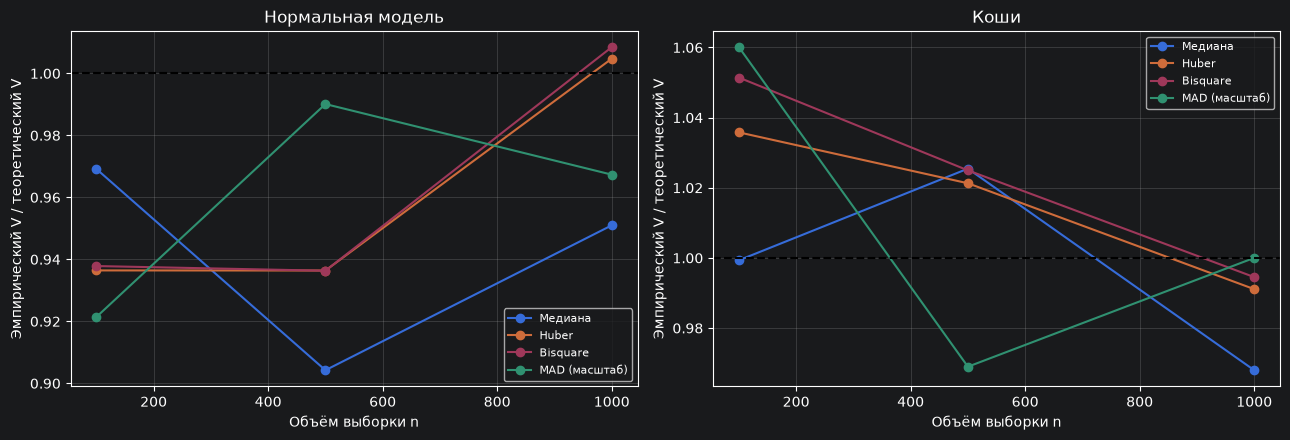

Неудачных решений в чистых моделях: 0


In [11]:
q_cauchy = cauchy.ppf(0.75)
assert np.isclose(q_cauchy, 1.0)
cauchy_theory = {'Медиана': np.pi**2 / 4,
                 'Huber': cauchy_moments['Huber'][2],
                 'Bisquare': cauchy_moments['Bisquare'][2],
                 'MAD (масштаб)': np.pi**2 / 4}
cauchy_check = variance_experiment('cauchy', repeats=2000, sample_sizes=[100, 500, 1000],
                                   rng_seed=45, q_scale=q_cauchy, theory=cauchy_theory)
display(cauchy_check.round(5))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, table, title in zip(axes, [normal_check, cauchy_check], ['Нормальная модель', 'Коши']):
    for name in ['Медиана', 'Huber', 'Bisquare', 'MAD (масштаб)']:
        rows = table[table['Метод'] == name]
        ax.plot(rows['n'], rows['Отношение'], 'o-', label=name)
    ax.axhline(1, color='black', linestyle='--')
    ax.set(xlabel='Объём выборки n', ylabel='Эмпирический V / теоретический V', title=title)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print('Неудачных решений в чистых моделях:',
      int(normal_check['Сбоев'].sum() + cauchy_check['Сбоев'].sum()))

При $n=1000$ в модели Коши получены эмпирические коэффициенты
$V_H=2.81722$ и $V_B=2.33745$ против теоретических 2.84251 и 2.35029.
У MAD эмпирический коэффициент равен 2.46746, теоретический —
$\pi^2/4\approx2.46740$. Неудачных решений в проведённых экспериментах нет.
В нормальной модели при $n=1000$ отношения эмпирических дисперсий к
теоретическим для Губера и bisquare равны 1.00475 и 1.00847.